In [125]:
%load_ext autoreload
%autoreload 2

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [131]:
import os
import tensorflow as tf
from mpl_toolkits.mplot3d import Axes3D  # noqa: F401 unused import
import matplotlib.pyplot as plt
import numpy as np
from tqdm import tqdm
from sklearn.manifold import TSNE

# local imports 
from pwa import PWA
from tools import *
from rietools import *
from bdiff import *
from wordnet_tools import *
from mnist_tools import *
from tensorflow.examples.tutorials.mnist import input_data

np.random.seed(123)
tf.set_random_seed(123)
Modes = tf.estimator.ModeKeys

In [132]:
def trainer(opts,data,visdata_train,visdata_test,epoch,nr_samples,shuffle,subset_len):
    #model
    model = PWA(opts)
    batch_size = opts['batch_size']
    #training loop
    for ep in range(epoch):
        if shuffle:
            np.random.shuffle(data)
        for iter in tqdm(range(nr_samples // batch_size)):
            #obtain a mini-batch
            batch = data[iter*batch_size:(iter+1)*batch_size,:]
            loss, mloss, rloss, kloss, mu, sigma= model.run_single_step(batch)
 
        print('[Epoch {}] Recon Loss: {}, MMD: {}'.format(ep,loss,mloss))
        print('Mean: {}, "Var": {}'.format(mu,np.exp(0.5*sigma)))
        if opts['dataset'] == 'bd':
            #draw_means(opts,visdata_train,model,treedepth=opts['treedepth'],
            #                 b=2,c=opts['c'],d=opts['input_dim'],subset_len=5)
            #draw_latent_tree(opts,visdata_test,model,treedepth=opts['treedepth'],
            #                 b=2,c=opts['c'],d=opts['input_dim'],subset_len=subset_len,plot_means=False)
            #draw_latent_tree(opts,visdata_test,model,treedepth=opts['treedepth'],
            #                 b=2,c=opts['c'],d=opts['input_dim'],subset_len=1,plot_means=False)

            
            z_test = model.transformer_mu(np.reshape(visdata_test[0:subset_len],[-1,opts['input_dim']]))
            
            #mean_tree = np.mean(visdata_test[0:subset_len],0,keepdims=True)
            #mean_tree = np.mean(mean_tree,2,keepdims=True)
            #draw_latent_tree_tsne(opts,mean_tree,treedepth=6,b=2,c=1,d=2,subset_len=1,plot_means=False)
            
            data_u_tree = visdata_train[0:subset_len]
            data_v_tree = np.reshape(z_test,[subset_len,opts['b']**(opts['treedepth']+1),opts['c'],opts['dim_z']])
            avg_dist_tree = np_compute_avg_distortion_tree(data_u_tree, data_v_tree, b=opts['b'], treedepth=opts['treedepth'], c=opts['c'])

            data_u = np.reshape(visdata_test[0:subset_len],[-1,opts['input_dim']])[0:20]
            data_v = z_test[0:20]
            avg_dist_all = np_compute_avg_distortion_all(data_u, data_v)
            print('Average distortion: Tree: {}, All, {}'.format(avg_dist_tree, avg_dist_all))
        else:
            z_test = model.transformer_mu(np.reshape(visdata_test,[-1,opts['input_dim']]))
            data_u = np.reshape(visdata_test,[-1,opts['input_dim']])
            data_v = z_test
            #draw_wordnet_tree(z_test)
            avg_dist_all = np_compute_avg_distortion_all(data_u, data_v)
            print('Average distortion: All, {}'.format(avg_dist_all))
            
    print('Done!')
    return model

In [139]:
def trainer_mnist(opts,epoch,nr_samples):
    #model
    model = PWA(opts)
    batch_size = opts['batch_size']
    mnist = input_data.read_data_sets('MNIST_data',one_hot=True)
    fmnist = input_data.read_data_sets('Fashion_MNIST_data',one_hot=True)
    from tqdm import tqdm
    #training loop
    for ep in range(epoch):
        for iter in tqdm(range(nr_samples // batch_size)):
            #obtain a mini-batch
            #tuple:images,labels
            if opts['dataset'] == 'mnist':
                #if opts['dataset'] == 'fmnist':
                #    mnist = fmnist

                batch = mnist.train.next_batch(batch_size)[0]
                if opts['binarize']:
                    batch = np.random.binomial(1,batch)
                loss, mloss, rloss, kloss, _, _ = model.run_single_step(batch)

            elif opts['dataset'] == 'celeba':
                loss, mloss, rloss, kloss = model.run_single_step(np.zeros(shape=(batch_size,784),dtype=float))

            #train: execute forward and backward pass
        print('[Epoch {}] Loss: {}, {}, {}'.format(ep,rloss,mloss,kloss))
    print('Done!')
    return model

In [134]:
def eval_tsne_distortion(X,subset_len,opts,tree=True):
    data_u = X[0:subset_len]
    if tree:
        X_embedded = TSNE(n_components=2,verbose=1).fit_transform(np.reshape(data_u,[-1,opts['input_dim']]))
        data_v = np.reshape(X_embedded,[data_u.shape[0],data_u.shape[1],data_u.shape[2],-1])
        avg_dist_tsne = np_compute_avg_distortion_tree_eucl(data_u, data_v)
    else:
        X_embedded = TSNE(n_components=2,verbose=1).fit_transform(np.reshape(data_u,[-1,opts['input_dim']]))
        data_v = X_embedded
        avg_dist_tsne = np_compute_avg_distortion_all_eucl(data_u, data_v)

    print('Average distortion: TSNE: {}'.format(avg_dist_tsne))
    return X_embedded, avg_dist_tsne


In [140]:
tf.reset_default_graph()
np.random.seed(4)
tf.set_random_seed(4)
opts = {}
opts['dataset'] = 'mnist'
opts['nw_type'] = 'simple'
opts['input_dim'] = 50
if opts['dataset'] == 'nnlm':
    opts['input_dim'] = 128
    opts['nw_type'] = 'mlp'
if opts['dataset'] == 'mnist':
    opts['input_dim'] = 784
    opts['nw_type'] = 'mlp'
    
opts['lr_adam'] = 1e-3
opts['lr_rsgd'] = 1e-3
opts['batch_size'] = 64
opts['nn_act_fn'] = tf.nn.relu
opts['beta_mmd'] = 10.0
opts['sigma_mmd'] = 1.0 # Laplacian kernel width
opts['mmd_q'] = 1
opts['varregnorm'] = 2 # L1 or L2
opts['lambda_mmd'] = 1.0 # variance regularizer weight to avoid variance collapse
opts['beta_kld'] = 10.0
opts['dim_z'] = 2
opts['hyp_c'] = 1.0
opts['use_expmap'] = False
opts['hyp_mu'] = False
opts['hyp_var'] = False
opts['scalar_dispersion'] = False
opts['init_std'] = 0.01
opts['use_bias'] = False
opts['init_bias'] = 0.0
opts['prior_var'] = 1.0
opts['reparam'] = 'hyp'
opts['b'] = 2
opts['treedepth'] = 6
opts['loss'] = 'l2' # l2 or bce loss
opts['recon_weight'] = 1.0
opts['c'] = 5 # number of noise points per vertex
opts['dec_mlr'] = False
opts['enc_act_mu'] = None #tf.nn.tanh #lambda x: tf.nn.leaky_relu(x,alpha=0.2)
opts['enc_act_sigma'] = None #tf.nn.tanh
opts['binarize'] = True

print(opts)
if opts['dataset'] == 'bd':
    X_train, X_train_flat, X_test = generate_tree_dataset(n_train=100,n_test=10,scale=1/opts['c'],
                                        treedepth=opts['treedepth'],b=opts['b'],c=opts['c'],d=opts['input_dim'],offset=1,
                                                     strict_norms=True,center=True,stricter_norms=False)
    eval_tsne_distortion(X_train,1,opts)
    #draw_latent_tree_tsne(opts,X_embedded,treedepth=opts['treedepth'],b=2,c=opts['c'],d=2,subset_len=1,plot_means=False)
    model = trainer(opts, data=X_train_flat, 
                visdata_train=X_train, visdata_test=X_test, epoch=100, nr_samples=len(X_train_flat), shuffle=True, subset_len=5)
    #draw_latent_tree(opts,X_train,model,treedepth=opts['treedepth'],
    #                         b=2,c=opts['c'],d=opts['input_dim'],subset_len=subset_len,plot_means=False)
    draw_latent_tree(opts,X_test,model,treedepth=opts['treedepth'],
                     b=2,c=opts['c'],d=opts['input_dim'],subset_len=8,plot_means=False)
    mean_tree = np.mean(X_test,0,keepdims=True)
    mean_tree = np.mean(mean_tree,2,keepdims=True)
    draw_latent_tree_tsne(opts,mean_tree,treedepth=6,b=2,c=1,d=2,subset_len=1,plot_means=False)        
elif opts['dataset'] == 'nnlm':
    X_train, X_test = load_wordnet_data('nnlm')
    #X_embedded, avg_dist_tsne = eval_tsne_distortion(X_train,X_train.shape[0],opts,tree=False)
    model = trainer(opts, data=X_train, 
                visdata_train=X_train, visdata_test=X_test, epoch=100, nr_samples=len(X_train), shuffle=False, subset_len=2)
    Z_test = model.transformer_mu(np.reshape(X_train,[-1,opts['input_dim']]))
    draw_wordnet_tree(Z_test,50)
else:
    model = trainer_mnist(opts, epoch=20, nr_samples=60000)
    recon(model)
    gen_grid(model)
    gen_circle(model)

{'recon_weight': 1.0, 'beta_mmd': 10.0, 'lr_adam': 0.001, 'enc_act_mu': None, 'batch_size': 64, 'loss': 'l2', 'reparam': 'hyp', 'lambda_mmd': 1.0, 'c': 5, 'init_bias': 0.0, 'binarize': True, 'b': 2, 'mmd_q': 1, 'beta_kld': 10.0, 'lr_rsgd': 0.001, 'hyp_var': False, 'init_std': 0.01, 'nn_act_fn': <function relu at 0x7f6fd606c598>, 'dec_mlr': False, 'dim_z': 2, 'use_bias': False, 'dataset': 'mnist', 'enc_act_sigma': None, 'hyp_mu': False, 'prior_var': 1.0, 'input_dim': 784, 'scalar_dispersion': False, 'varregnorm': 2, 'nw_type': 'mlp', 'hyp_c': 1.0, 'sigma_mmd': 1.0, 'treedepth': 6, 'use_expmap': False}
Tensor("sub_155:0", shape=(?, 2), dtype=float32)
INFO:tensorflow:Summary name var/enc_fc1/kernel:0 is illegal; using var/enc_fc1/kernel_0 instead.


I0523 14:49:16.256506 140119291660032 summary_op_util.py:92] Summary name var/enc_fc1/kernel:0 is illegal; using var/enc_fc1/kernel_0 instead.


INFO:tensorflow:Summary name var/enc_fc1/bias:0 is illegal; using var/enc_fc1/bias_0 instead.


I0523 14:49:16.264899 140119291660032 summary_op_util.py:92] Summary name var/enc_fc1/bias:0 is illegal; using var/enc_fc1/bias_0 instead.


INFO:tensorflow:Summary name var/enc_fc2/kernel:0 is illegal; using var/enc_fc2/kernel_0 instead.


...

[Epoch 17] Loss: 1376.95654296875, 0.05026772618293762, nan


  1%|          | 9/937 [00:00<00:10, 88.37it/s]

[Epoch 18] Loss: 1515.014892578125, 0.04377290606498718, nan


100%|██████████| 937/937 [00:10<00:00, 88.23it/s]

[Epoch 19] Loss: 1414.1781005859375, 0.04646776244044304, nan
Done!


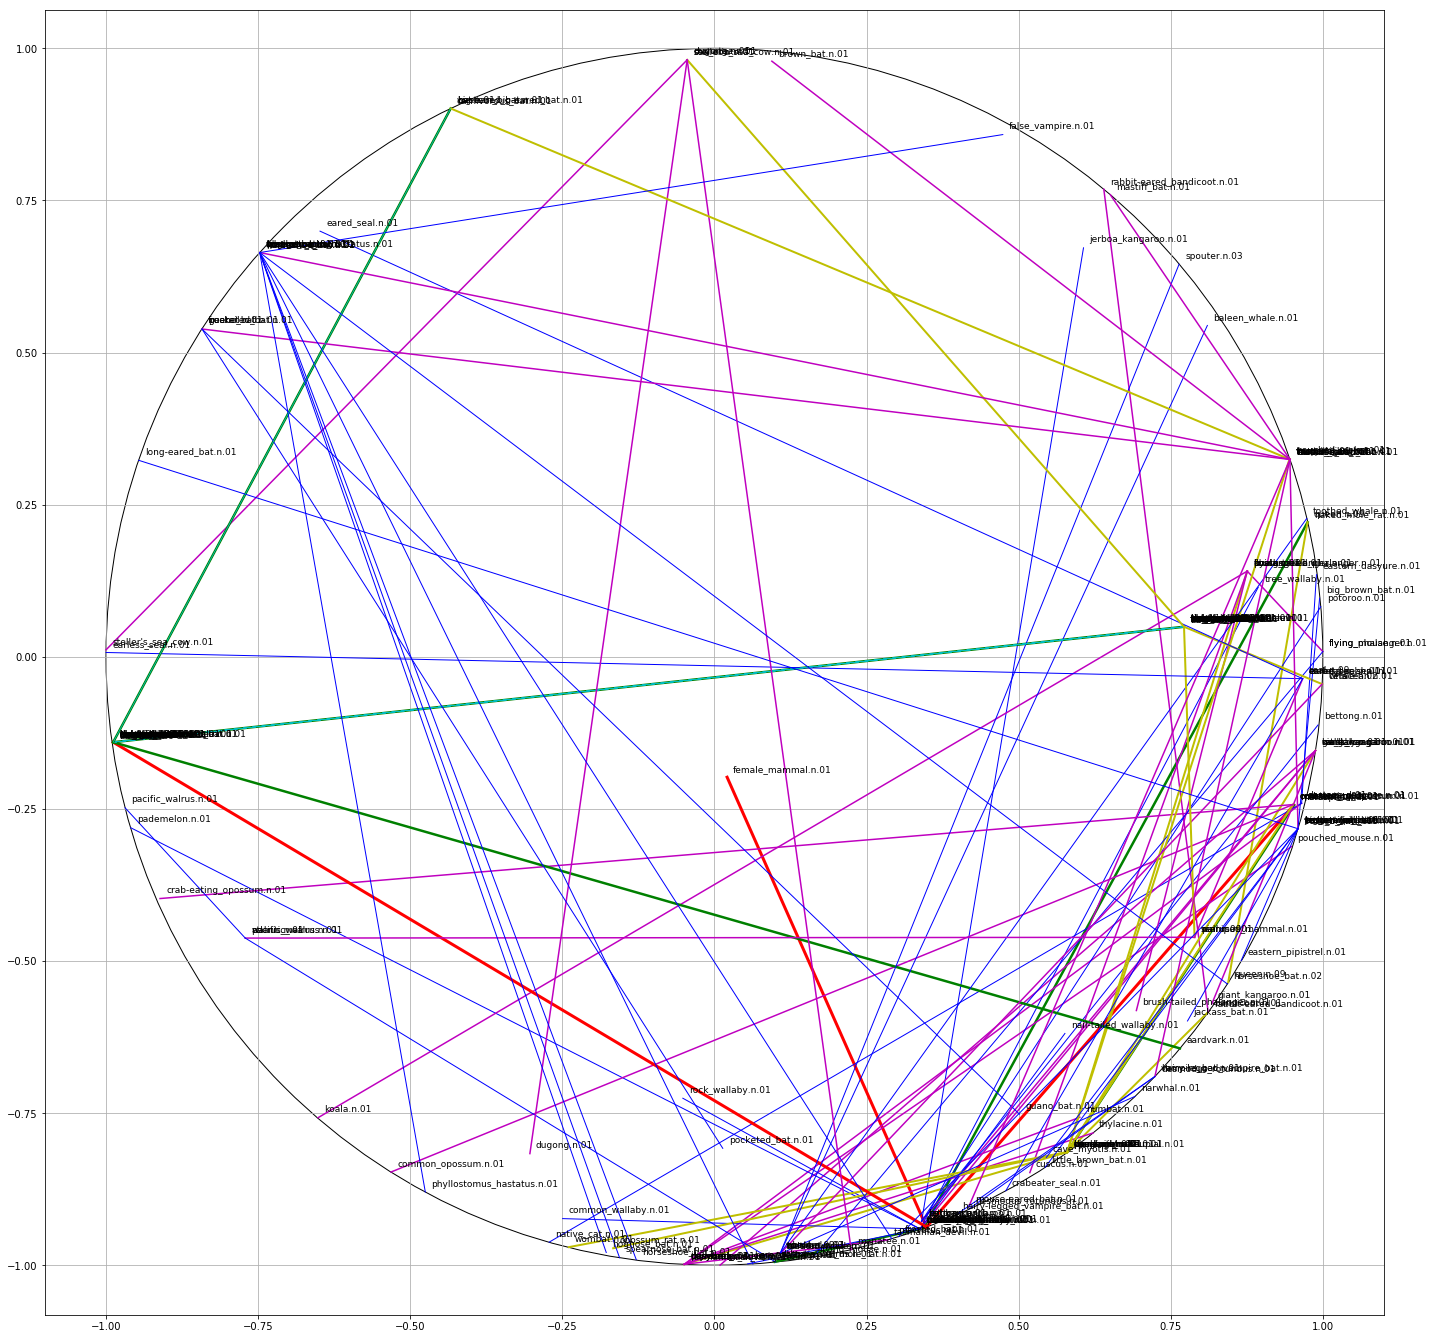

0

In [104]:
draw_wordnet_tree(Z_test,100)


Generating trees...
[0. 0.]
Done


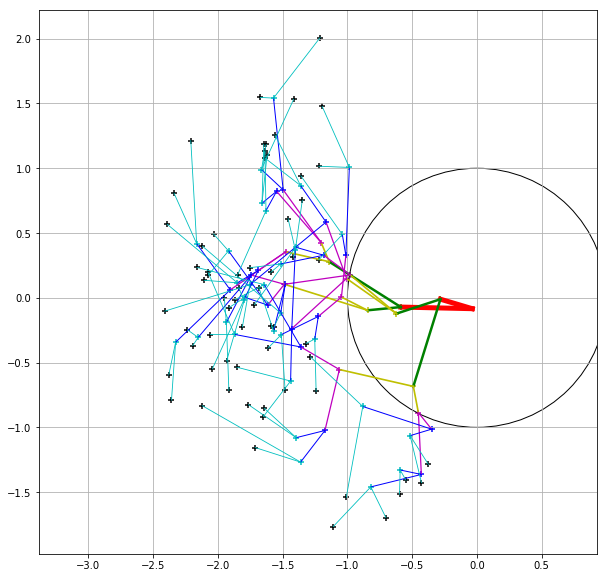

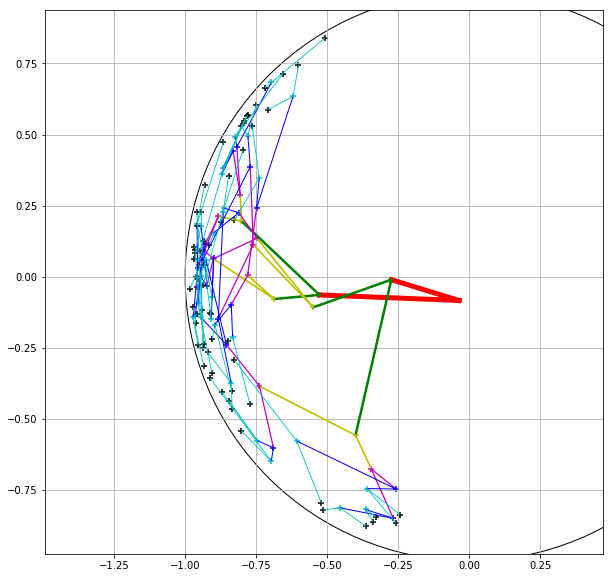

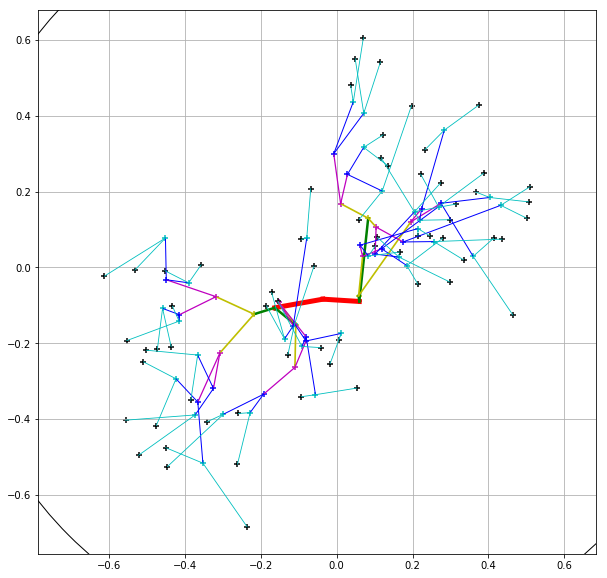

2.210276111728413


In [109]:
X_train, X_train_flat, X_test = generate_tree_dataset(n_train=10,n_test=10,scale=1,
                                        treedepth=6,b=2,c=1,d=2,offset=1,
                                                     strict_norms=True,center=True,stricter_norms=False)

# test exp and logmap
X_train_pd = np_exp_map(X_train_flat)
X_logmap = np_log_map(X_train_pd)
draw_latent_tree_tsne(opts,X_train_flat,treedepth=6,b=2,c=1,d=2,subset_len=1,plot_means=False)
draw_latent_tree_tsne(opts,X_train_pd,treedepth=6,b=2,c=1,d=2,subset_len=1,plot_means=False)
#draw_latent_tree_tsne(opts,X_logmap,treedepth=6,b=2,c=1,d=2,subset_len=1,plot_means=False)

mean_tree = np.mean(X_train,0,keepdims=True)
mean_tree = np.mean(mean_tree,2,keepdims=True)
draw_latent_tree_tsne(opts,mean_tree,treedepth=6,b=2,c=1,d=2,subset_len=1,plot_means=False)

print(np.max(X_train_flat))

In [ ]:
draw_means(opts,X_train,model,treedepth=opts['treedepth'],
                             b=2,c=opts['c'],d=opts['input_dim'],subset_len=10)
draw_latent_tree(opts,X_train,model,treedepth=opts['treedepth'],
                             b=2,c=opts['c'],d=opts['input_dim'],subset_len=10,plot_means=False)

[nltk_data] Downloading package wordnet to /home/ivan/nltk_data...
[nltk_data]   Package wordnet is already up-to-date!
[nltk_data] Downloading package punkt to /home/ivan/nltk_data...
[nltk_data]   Package punkt is already up-to-date!


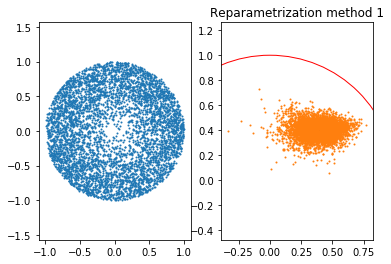

Mean: [0.4 0.4] Var:  [0.19999999 0.09999999]


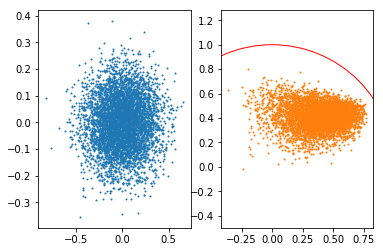

Mean: [0.4 0.4] Var:  [0.19999999 0.09999999]


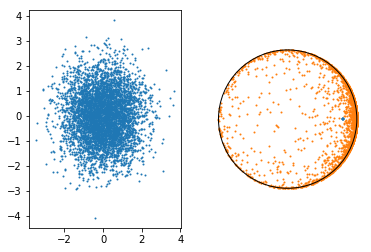

In [87]:
def sample_gauss_pd(shape,oversample=5,radius=0.85,sigma=1.0):
    # rejection sample in Poincaré disk
    d = shape[1]
    n_samples = tf.reduce_prod(shape)*oversample
    phi = tf.random_uniform([n_samples])*2*np.pi
    p = tf.random_uniform([n_samples])
    r = tf.acosh(1+p*(tf.cosh(radius-1e-5)-1)) # support (-3sigma, 3sigma)
    #unif_samples = tf.stack([tf.sinh(r)*tf.cos(phi), tf.sinh(r)*tf.sin(phi)],axis=1)
    unif_samples = tf.stack([r*tf.cos(phi), r*tf.sin(phi)],axis=1)

    # zero mean, unit sigma in half plane
    mean = tf.constant(np.array([[0.0,0.0]]),tf.float32)
    
    p_samples = gauss_prob_pd(unif_samples,mean,sigma)
    # accept in proportion to highest
    max_value = tf.reduce_max(p_samples)
    accepted = tf.squeeze(tf.where(tf.random_uniform([n_samples]) < (p_samples/max_value)),1)
    #accepted = tf.where(tf.random_uniform([n_samples]) < (p_samples/max_value),unif_samples,tf.zeros_like(unif_samples))
    # select the samples - make sure it's enough
    u = tf.boolean_mask(unif_samples[:,0],accepted)
    v = tf.boolean_mask(unif_samples[:,1],accepted)
    # transform samples using cayley mapping z = (w-i)/(w+i) - project to unit disk
    disk_samples = tf.stack([u,v],axis=1)
    idx = tf.cast(tf.range(tf.reduce_prod(shape)/2),tf.int32)
    return tf.reshape(tf.gather(disk_samples,idx),shape)

def sample_gauss_hn(shape,oversample=5,radius=1.0,sigma=1.0,alpha=0.3):
    # rejection sample in Poincaré disk
    n = shape[0] # batch_sizes
    d = shape[1]    
    n_samples = shape[0]*oversample
    p = tf.random_uniform([n_samples])
    #r = tf.acosh(1+p*(tf.cosh(radius-1e-5)-1)) # support (-3sigma, 3sigma)
    d_fl = tf.cast(d,tf.float32)
    r = tf.pow((p*tf.pow(radius,d_fl)),(1/d_fl))
    f_r = gauss_prob_pd_r(r,sigma)
    
    M = tf.reduce_max(f_r/g_r) # empirical M
    accepted = tf.random_uniform([n_samples]) < (f_r/(M*g_r))
    r_a = tf.boolean_mask(r,accepted)
    #dir_a = tf.boolean_mask(direction,accepted)

    direction = sample_unit_sphere(n,d)
    samples = tf.expand_dims(r_a[:n],1)*direction
    unif_samples = tf.expand_dims(r[:n],1)*direction
    return tf.reshape(samples[:n],shape)

def sample_gauss_hn_(shape,oversample=5,radius=1.0,sigma=1.0):
    # rejection sample in Poincaré disk
    n = shape[0] # batch_sizes
    d = shape[1]    
    n_samples = shape[0]*oversample
    p = tf.random_uniform([n_samples])
    #r = tf.acosh(1+p*(tf.cosh(radius-1e-5)-1)) # support (-3sigma, 3sigma)
    d_fl = tf.cast(d,tf.float32)
    r = tf.pow((p*tf.pow(radius,d_fl)),(1/d_fl))
    f_r = gauss_prob_pd_r(r,sigma)
    g_r = 1/radius#tf.exp(r) # proposal
    #g_r = alpha*tf.exp(alpha*(r-radius)) # proposal

    M = tf.reduce_max(f_r/g_r) # empirical M
    accepted = tf.random_uniform([n_samples]) < (f_r/(M*g_r))
    r_a = tf.boolean_mask(r,accepted)
    #dir_a = tf.boolean_mask(direction,accepted)

    direction = sample_unit_sphere(n,d)
    samples = tf.expand_dims(r_a[:n],1)*direction
    unif_samples = tf.expand_dims(r[:n],1)*direction
    return tf.reshape(samples[:n],shape)

def reparam_h(mu,log_sigma,radius=0.88,c=1.0,scalar_dispersion=False,use_expmap=False,prior_var=1.0):
    sigma = tf.exp(0.5*log_sigma)
    if use_expmap:
        eps_sample = exp_map(np.sqrt(prior_var)*tf.random_normal(tf.shape(mu)),c)
    else:
        #eps_sample = sample_gauss_pd(tf.shape(mu),radius=radius)
        #eps_sample = project_hyp_vec(sample_gauss_pd(tf.shape(mu),radius=radius,sigma=prior_var),c)
        #eps_sample = sample_gauss_hn_(tf.shape(mu),radius=radius,sigma=prior_var)
        eps_sample = project_hyp_vec(sample_gauss_hn_(tf.shape(mu),radius=radius,sigma=prior_var),c)

    if scalar_dispersion:
        tsf_eps = mobius_scalar_mul(sigma,eps_sample,c)
    else:
        Sigma = tf.matrix_diag(sigma)
        tsf_eps = mobius_lin(Sigma,eps_sample,c)
        
    z = mobius_add(mu,tsf_eps,c)
    #z = exp_map_x(mu,eps_sample,c)
    #return add_res, project_hyp_vec(prior_sample,c)
    return z, eps_sample

def reparam_h_wrapped(mu,log_sigma,c=1.0,prior_var=1.0):
    sigma = tf.exp(0.5*log_sigma)
    #scaled_eps = exp_map(sigma*tf.random_normal(tf.shape(mu))/tf_lambda_x(mu,c),c)
    scaled_eps = tf.random_normal(tf.shape(mu))*sigma
    z = exp_map_x(mu,scaled_eps,c)
    #return add_res, project_hyp_vec(prior_sample,c)
    return z, scaled_eps

def plot_scatter_disk(x,savefig=None):
    plt.figure(figsize=(12,12)) 
    ax = plt.gca()
    circle = plt.Circle((0, 0), 1.0, color='k', fill=False, linewidth=2.0)
    ax.add_artist(circle)
    plt.axis('off')
    ax.set_xlim([-1.1,1.1])
    ax.set_ylim([-1.1,1.1])

    #plt.axis('equal')
    plt.scatter(x[:,0],x[:,1],s=20)
    if savefig is not None:
        plt.savefig(savefig,transparent=True)
    
def plot_scatter_eucl(x,savefig=None):
    plt.figure()
    plt.axis('off')
    plt.axis('equal')
    plt.scatter(x[:,0],x[:,1],s=2)
    if savefig is not None:
        plt.savefig(savefig,transparent=True)
        
        
N = 5000
mu_ = np.array([0.4,0.4],dtype=np.float32)
log_sigma_ = np.array([np.log(0.2)*2, np.log(0.1)*2],dtype=np.float32)
mu = tf.constant(mu_)
log_sigma = tf.constant(log_sigma_)
mu =  tf.tile(tf.expand_dims(mu,0),[N,1])
log_sigma =  tf.tile(tf.expand_dims(log_sigma,0),[N,1])

################################################

z, eps_sample = reparam_h(mu, log_sigma, radius=1.0, 
                                c=1.0, use_expmap=False, 
                                scalar_dispersion=False,
                                prior_var=1.0)

t1 = log_map(eps_sample)
t2 = log_sigma*t1
t3 = exp_map(t2)

session = tf.Session()

z_res,eps,int1,int2,int3 = session.run([z,eps_sample,t1,t2,t3])
plt.subplot(1,2,1)
plt.scatter(eps[:,0],eps[:,1],s=1)
plt.axis('equal')

plt.subplot(1,2,2)
plt.scatter(mu_[0],mu_[1],s=20,marker='+')
plt.scatter(z_res[:,0],z_res[:,1],s=1)
ax = plt.gca()
circle = plt.Circle((0, 0), 1.0, color='r', fill=False)
ax.add_artist(circle)
plt.title('Reparametrization method 1')
#plt.axis('off')
plt.axis('equal')
plt.show()

################################################

z, eps_sample = reparam_h_wrapped(mu, log_sigma, c=1.0, prior_var=1.0)

z_res,eps,int1,int2,int3 = session.run([z,eps_sample,t1,t2,t3])

t1 = log_map(eps_sample)
t2 = tf.exp(0.5*log_sigma)*t1
t3 = exp_map_x(mu, t2, c=1.0)

plt.figure(2)
plt.title('Reparametrization method 2')
print("Mean:", mu_,"Var: ", np.exp(0.5*log_sigma_))
plt.subplot(1,2,1)
plt.scatter(eps[:,0],eps[:,1],s=1)
plt.subplot(1,2,2)
plt.scatter(mu_[0],mu_[1],s=20,marker='+')
plt.scatter(z_res[:,0],z_res[:,1],s=1)
ax = plt.gca()
circle = plt.Circle((0, 0), 1.0, color='r', fill=False)
ax.add_artist(circle)
plt.axis('equal')
#plt.axis('off')
plt.show()

################################################

import tensorflow_probability as tfp
tfd = tfp.distributions
mu__ = [0.8, 0.]
cov__ = [[ 1.0,  0.0],
       [ 0.0,  1.0]]
mu = tf.constant([mu__])
cov = tf.constant(cov__)
mvn = tfd.MultivariateNormalFullCovariance(
    loc=[0.0,0.0],
    covariance_matrix=cov)

eucl_samples = mvn.sample(N)
expmap_samples = exp_map_x(mu, eucl_samples, c=1.0)
z_,z_res  = session.run([eucl_samples,expmap_samples])

plt.figure(3)
plt.title('Reparametrization method 3')
print("Mean:", mu_,"Var: ", np.exp(0.5*log_sigma_))
#plt.scatter(z[:,0],z[:,1],s=1)
plt.subplot(1,2,1)
plt.scatter(z_[:,0],z_[:,1],s=1)
plt.subplot(1,2,2)
plt.scatter(mu__[0],mu__[1],s=20,marker='+')
plt.scatter(z_res[:,0],z_res[:,1],s=1)
ax = plt.gca()
circle = plt.Circle((0, 0), 1.0, color='k', fill=False)
ax.add_artist(circle)
plt.axis('equal')
plt.axis('off')
plt.show()


#plt.savefig("reparam.png",transparent=True)


(array([  4.,   5.,   5.,  11.,  15.,  23.,  37.,  50.,  71.,  97.,  92.,
        106., 115.,  88.,  95.,  62.,  44.,  24.,  22.,  15.,   6.,  10.,
          0.,   1.,   1.,   0.,   1.]),
 array([-22.75861211, -20.84873402, -18.93885593, -17.02897784,
        -15.11909975, -13.20922166, -11.29934358,  -9.38946549,
         -7.4795874 ,  -5.56970931,  -3.65983122,  -1.74995313,
          0.15992495,   2.06980304,   3.97968113,   5.88955922,
          7.79943731,   9.7093154 ,  11.61919348,  13.52907157,
         15.43894966,  17.34882775,  19.25870584,  21.16858393,
         23.07846201,  24.9883401 ,  26.89821819,  28.80809628]),
 <a list of 27 Patch objects>)

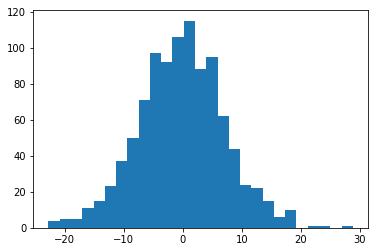

In [54]:
dots = []
for i in range(1000): 
    dots.append(np.dot(np.random.randn(50),np.random.randn(50)))

dots = np.array(dots)
data = dots
binwidth = 0.1
#plt.hist(data, bins=range(min(data), max(data) + binwidth, binwidth))
plt.hist(dots, bins='auto')

In [146]:
a = np.linspace(-1000,1000)
b = np.exp_map(a)